**Eye-Tracking & Neurocognitive Intelligence | Eye-Tracking Foundations & Signal Analysis | Presented by: Reza Saadatyar (2026)**

**03 | I-VT and I-DT Eye-Movement Event Detection**

![Conceptual workflow for stage 03](../../images/03_ivt_idt_event_detection.svg)

**Objective:** Derive transparent, explicitly parameterised eye-movement events from a reusable motion representation.

**Dataset:** Notebook 02 current preprocessed-sample table; no raw source reread.

**Notebook scope:** Implements I-VT and fixation-only I-DT; vendor labels are reference annotations, not ground truth.

**Execution status:** Source code prepared. No original-data results are claimed until this notebook is executed with the specified release.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_tracking_foundations")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

# ------------------------ 4. Study Research Utilities ------------------------
from core.stage_outputs import ensure_stage_inputs
from gaze_source import read_stage
from eye_events import ivt_labels, idt_labels, extract_events, label_agreement

# --------------------- 5. Output and Presentation Setup ----------------------
output_dir = root / "eye_tracking_foundations" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(10, 4),
)
print("Current outputs:", output_dir)


Repository updated.
Current outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output


**02. Recover Prepared Motion Samples**

Use Notebook 02's current prepared samples. Prior-stage ZIP recovery is
supported for a fresh Colab runtime with no repeated source extraction.


In [3]:
# ==================== 02. Recover Prepared Motion Samples ====================

ensure_stage_inputs(output_dir, 2, ("02_preprocessed_samples.csv",))
prepared = read_stage(
    output_dir / "02_preprocessed_samples.csv",
    ("record_id","sample_index","n","x_smooth","y_smooth", "valid_for_motion", "segment_id","velocity_dva_s"),
)


**03. Compute I-VT and I-DT Sample Assignments**

I-VT uses an initial 30-dva/s threshold with minimum fixation/saccade
durations of 80/6 ms. I-DT uses 1-dva spatial dispersion over at least
80 ms and assigns **fixations only**; its other samples remain unknown.
These settings are educational starting points and are not fitted to vendor
labels. The later Notebook 06 examines sensitivity systematically.


In [4]:
# =============== 03. Compute I-VT and I-DT Sample Assignments ================

IVT_DVA_S = 30.0
IDT_DISP_DVA = 1.0
assigned=[]
event_tables=[]
vendor_rows=[]
for rid, part in prepared.groupby("record_id", sort=True):
    part = part.sort_values("sample_index").reset_index(drop=True)
    ivt = ivt_labels(part, threshold_dva_s=IVT_DVA_S)
    idt = idt_labels(part, dispersion_dva=IDT_DISP_DVA)
    assigned.append(pd.DataFrame({
        "record_id":rid, "sample_index":part.sample_index,
        "ivt_label":ivt, "idt_label":idt,
    }))
    event_tables.extend((extract_events(part, ivt, "IVT"),
                         extract_events(part, idt, "IDT")))
    vendor_rows.append({"record_id":rid, **label_agreement(part, ivt)})
labels = pd.concat(assigned, ignore_index=True)
events = pd.concat(event_tables, ignore_index=True)
vendor = pd.DataFrame(vendor_rows)
assert not labels.duplicated(["record_id", "sample_index"]).any()
labels.to_csv(output_dir / "03_sample_labels.csv", index=False)
events.to_csv(output_dir / "03_events.csv", index=False)
vendor.to_csv(output_dir / "03_vendor_agreement.csv", index=False)
display(events.groupby(["method","event_type"]).size().rename("n_events"))


method  event_type
IDT     fixation      5409
IVT     fixation      7015
        saccade       9304
Name: n_events, dtype: int64

**04. Compare Predicted Labels and Vendor Coverage**

Agreement is calculated only where the source vendor code is known and the
algorithm produced an evaluable class. Report eligibility and coverage
beside agreement; do not call this an independent accuracy estimate.


In [5]:
# ============= 04. Compare Predicted Labels and Vendor Coverage ==============

display(vendor)
print("Unknown IVT samples:", (labels.ivt_label=="unknown").sum())
print("I-DT does not classify saccades or blinks.")


,record_id,eligible_samples,vendor_coverage_fraction,predicted_evaluable_fraction,sample_agreement
0,S_1001_S1_FXS,14065,0.999469,0.932878,0.995308
1,S_1001_S1_HSS,76493,0.999921,0.755121,0.985018
2,S_1001_S1_RAN,88173,0.999921,0.871240,0.982897
3,S_1001_S1_TEX,48138,0.999867,0.799196,0.974802
4,S_1002_S1_FXS,8399,0.997147,0.557185,0.991189
5,S_1002_S1_HSS,55350,0.999921,0.546327,0.983631
6,S_1002_S1_RAN,51068,0.999921,0.504131,0.981064
7,S_1002_S1_TEX,31828,0.999867,0.528380,0.961355
8,S_1003_S1_FXS,14699,0.999469,0.975123,0.996326
9,S_1003_S1_HSS,94895,0.999921,0.936476,0.985700


Unknown IVT samples: 888893
I-DT does not classify saccades or blinks.


**05. Display Detected Events on a Gaze Trace**

Display a short interval and distinguish unknown segments. The figure is a
computed result based on saved prepared samples and computed I-VT labels.


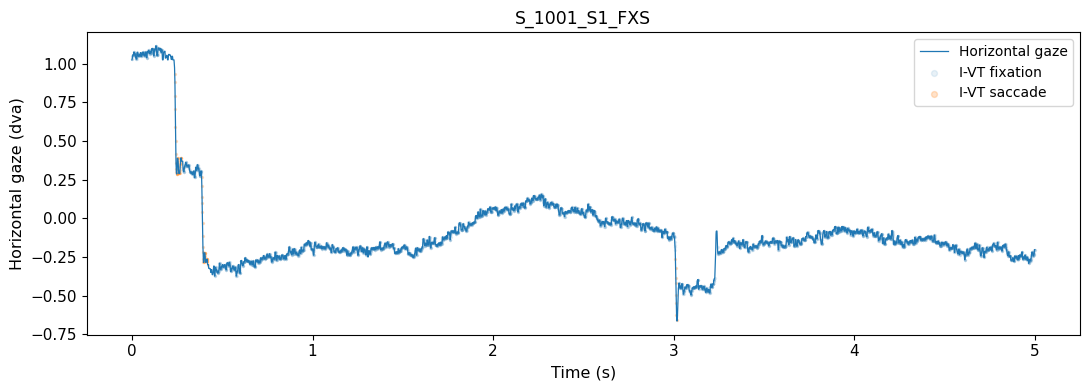

In [6]:
# ================ 05. Display Detected Events on a Gaze Trace ================

rid = str(prepared.record_id.iloc[0])
part = prepared[prepared.record_id.eq(rid)].head(5000).copy()
labs = labels[labels.record_id.eq(rid)].head(len(part))
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(part.time_s, part.x_smooth, lw=0.9, label="Horizontal gaze")
for kind, alpha in [("fixation",0.10),("saccade",0.22)]:
    mask = labs.ivt_label.to_numpy()==kind
    ax.scatter(part.time_s.to_numpy()[mask], part.x_smooth.to_numpy()[mask],
               s=2, alpha=alpha, label=f"I-VT {kind}")
ax.set(xlabel="Time (s)",ylabel="Horizontal gaze (dva)",title=rid)
ax.legend(loc="upper right",markerscale=3)
fig.tight_layout()
save_figure(fig, output_dir / "03_detector_trace.png")
plt.show()


**06. Download Event and Label Outputs**

Notebook 04 consumes the stored ~03_events.csv~ and prepared motion samples;
Notebook 06 uses saved sample labels and vendor coverage for sensitivity
analysis. No detector is hidden in the later reporting stages.


In [7]:
# =================== 06. Download Event and Label Outputs ====================

print("Event rows:",len(events),"Sample predictions:",len(labels))
download_outputs_from_colab("eye_tracking_foundations/output", "03")


Event rows: 21728 Sample predictions: 2778008
------------------------------------------------------------------------
Notebook 03
Files packaged: 4
  + 03_detector_trace.png
  + 03_events.csv
  + 03_sample_labels.csv
  + 03_vendor_agreement.csv
Download ZIP from Colab Contents: /content/eye_tracking_foundations_Notebook_03_Outputs.zip
